# 15 - Final Pipeline and New Data Prediction
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 6 - Deployment

**Project stage:** 15 of 16 - packages every prior decision into one reusable prediction function

---

## 1. Objective

This notebook builds the bridge from "a finished analysis" to "a usable system." We will:

1. Load the exact saved artifacts from earlier notebooks - the fitted preprocessing pipeline (Notebook 07), the final clustering model (Notebook 13), and the segment name mapping (Notebook 14).
2. Build one function that takes a **new booking record** and returns a cluster ID and business segment name, following the flow: raw booking -> preprocessing -> clustering model -> cluster ID -> segment name.
3. Demonstrate it on four realistic new bookings, and confirm the assignments make sense against the segment profiles built in Notebook 14.
4. Surface a genuine, easy-to-miss complication found while building this: one of our core clustering features (`room_type_mismatch`) depends on information (`assigned_room_type`) that usually isn't known yet at the moment a booking is made - and show how the function handles that honestly.
5. State plainly and specifically what this deployment can and cannot promise about future bookings.

## 2. Business Context

None of the work in Notebooks 01-14 is useful to the hotel unless it can be applied to bookings that come in after this analysis was done. This notebook is that final, practical step - turning "we found four segments" into "here is how the front desk, marketing, or revenue system could find out which segment a specific new booking belongs to."

This is also where an important, honest limitation becomes unavoidable to confront directly: our final clustering model was trained on features derived from complete, historical records. A brand-new booking, at the moment it's made, doesn't have all of that information yet. Good deployment work means handling that gap explicitly, not pretending it doesn't exist.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# joblib / json: loading the saved pipeline, model, and configuration
import joblib
import json

# sklearn: PCA, purely for the illustrative visualization in Section 5.6
from sklearn.decomposition import PCA

# os: portable file paths
import os


## 4. Configuration

In [2]:
PREPROCESSING_PIPELINE_PATH = "../models/preprocessing_pipeline.joblib"
FINAL_MODEL_PATH = "../models/final_kmeans_model.joblib"
FEATURE_LISTS_PATH = "../config/feature_lists.json"
PREPROCESSED_FEATURE_NAMES_PATH = "../config/preprocessed_feature_names.json"
SEGMENT_MAPPING_PATH = "../reports/tables/14_segment_name_mapping.csv"
PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"

FIGURES_DIR = "../reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 160)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load Every Saved Artifact

In [3]:
preprocessing_pipeline = joblib.load(PREPROCESSING_PIPELINE_PATH)
final_model = joblib.load(FINAL_MODEL_PATH)

with open(FEATURE_LISTS_PATH, "r") as f:
    feature_lists = json.load(f)

with open(PREPROCESSED_FEATURE_NAMES_PATH, "r") as f:
    preprocessed_feature_names = json.load(f)

segment_mapping = pd.read_csv(SEGMENT_MAPPING_PATH)

CORE_NUMERIC_FEATURES = feature_lists["core_numeric_features"]
CORE_CATEGORICAL_FEATURES = feature_lists["core_categorical_features"]

print("Preprocessing pipeline loaded.")
print("Final model loaded:", type(final_model).__name__, "with", final_model.n_clusters, "clusters")
print()
segment_mapping[["cluster_id", "segment_name"]]


Preprocessing pipeline loaded.
Final model loaded: KMeans with 4 clusters



,cluster_id,segment_name
0,0,High-Value Family & Group Travelers
1,1,"Early-Planning, Long-Stay Bookers"
2,2,"Loyal, Low-Risk Repeat Guests"
3,3,Mainstream Online City-Hotel Guests


### 5.2 The Prediction Function

**What this function does, step by step:**
1. Accepts a new booking as a Python dictionary of raw field values.
2. Checks that every required field is present, filling in a documented default for `room_type_mismatch` if it's missing (see Section 5.4 for why this matters).
3. Builds a one-row DataFrame in exactly the column order the preprocessing pipeline expects.
4. Applies the **already-fitted** preprocessing pipeline (`transform`, not `fit_transform` - we must never refit on new data, or we'd be using a different scaling/encoding than the one the model was trained on).
5. Predicts the cluster ID using the final K-Means model.
6. Looks up and returns the corresponding business segment name.

In [4]:
def assign_segment(raw_booking: dict, verbose: bool = True) -> dict:
    """
    Given a new booking as a dictionary of raw field values, return the
    predicted cluster ID and business segment name.

    Required keys: every value in CORE_NUMERIC_FEATURES and
    CORE_CATEGORICAL_FEATURES. If 'room_type_mismatch' is not provided
    (common for a booking that hasn't checked in yet - see Section 5.4),
    it defaults to 0 (assume no mismatch), and this function will warn
    about that assumption.
    """
    booking = dict(raw_booking)  # avoid mutating the caller's dictionary

    # Handle the room_type_mismatch special case explicitly (see Section 5.4)
    used_default_room_match = False
    if "room_type_mismatch" not in booking:
        booking["room_type_mismatch"] = 0
        used_default_room_match = True

    # Check every other required field is present
    required_fields = CORE_NUMERIC_FEATURES + CORE_CATEGORICAL_FEATURES
    missing_fields = [field for field in required_fields if field not in booking]
    if missing_fields:
        raise ValueError(f"Missing required booking fields: {missing_fields}")

    # Build a one-row DataFrame in the exact column order the pipeline expects
    booking_row = pd.DataFrame([booking])[required_fields]

    # Apply the already-fitted preprocessing pipeline (transform, never fit_transform)
    preprocessed_row = preprocessing_pipeline.transform(booking_row)
    preprocessed_row_df = pd.DataFrame(preprocessed_row, columns=preprocessed_feature_names)

    # Predict the cluster
    cluster_id = int(final_model.predict(preprocessed_row_df)[0])

    # Look up the business segment name
    segment_name = segment_mapping.loc[segment_mapping["cluster_id"] == cluster_id, "segment_name"].values[0]

    # Compute distance to every cluster centroid, as a simple confidence signal
    distances_to_centroids = np.linalg.norm(
        final_model.cluster_centers_ - preprocessed_row_df.values, axis=1
    )

    result = {
        "cluster_id": cluster_id,
        "segment_name": segment_name,
        "distance_to_assigned_centroid": round(float(distances_to_centroids[cluster_id]), 3),
        "distance_to_all_centroids": [round(float(d), 3) for d in distances_to_centroids],
        "used_default_room_type_mismatch": used_default_room_match,
    }

    if verbose:
        print(f"Cluster ID: {result['cluster_id']}")
        print(f"Segment: {result['segment_name']}")
        print(f"Distance to assigned cluster's centroid: {result['distance_to_assigned_centroid']}")
        if used_default_room_match:
            print("Note: 'room_type_mismatch' was not provided and defaulted to 0 (assumed no mismatch).")

    return result


### 5.3 Demonstrate on Four Realistic New Bookings

In [5]:
example_bookings = {
    "Family resort booking": {
        "lead_time": 45, "stays_in_weekend_nights": 2, "stays_in_week_nights": 3,
        "adults": 2, "children": 1, "babies": 0, "adr": 150.0,
        "required_car_parking_spaces": 1, "total_of_special_requests": 2, "booking_changes": 0,
        "is_repeated_guest": 0, "previous_cancellations": 0, "room_type_mismatch": 0,
        "hotel": "Resort Hotel", "meal": "HB", "market_segment": "Online TA",
        "distribution_channel": "TA/TO", "deposit_type": "No Deposit", "customer_type": "Transient",
    },
    "Long lead-time group booking": {
        "lead_time": 250, "stays_in_weekend_nights": 2, "stays_in_week_nights": 6,
        "adults": 2, "children": 0, "babies": 0, "adr": 85.0,
        "required_car_parking_spaces": 0, "total_of_special_requests": 0, "booking_changes": 1,
        "is_repeated_guest": 0, "previous_cancellations": 0, "room_type_mismatch": 0,
        "hotel": "City Hotel", "meal": "BB", "market_segment": "Offline TA/TO",
        "distribution_channel": "TA/TO", "deposit_type": "Non Refund", "customer_type": "Transient-Party",
    },
    "Loyal short-lead booking": {
        "lead_time": 10, "stays_in_weekend_nights": 1, "stays_in_week_nights": 1,
        "adults": 1, "children": 0, "babies": 0, "adr": 70.0,
        "required_car_parking_spaces": 0, "total_of_special_requests": 0, "booking_changes": 0,
        "is_repeated_guest": 1, "previous_cancellations": 0, "room_type_mismatch": 0,
        "hotel": "City Hotel", "meal": "BB", "market_segment": "Direct",
        "distribution_channel": "Direct", "deposit_type": "No Deposit", "customer_type": "Transient",
    },
    "Mainstream city online booking": {
        "lead_time": 60, "stays_in_weekend_nights": 1, "stays_in_week_nights": 2,
        "adults": 2, "children": 0, "babies": 0, "adr": 105.0,
        "required_car_parking_spaces": 0, "total_of_special_requests": 1, "booking_changes": 0,
        "is_repeated_guest": 0, "previous_cancellations": 0, "room_type_mismatch": 0,
        "hotel": "City Hotel", "meal": "BB", "market_segment": "Online TA",
        "distribution_channel": "TA/TO", "deposit_type": "No Deposit", "customer_type": "Transient",
    },
}

demo_results = {}
for booking_name, booking_data in example_bookings.items():
    print(f"--- {booking_name} ---")
    demo_results[booking_name] = assign_segment(booking_data)
    print()


--- Family resort booking ---
Cluster ID: 0
Segment: High-Value Family & Group Travelers
Distance to assigned cluster's centroid: 2.176

--- Long lead-time group booking ---
Cluster ID: 1
Segment: Early-Planning, Long-Stay Bookers
Distance to assigned cluster's centroid: 2.338

--- Loyal short-lead booking ---
Cluster ID: 2
Segment: Loyal, Low-Risk Repeat Guests
Distance to assigned cluster's centroid: 1.829

--- Mainstream city online booking ---
Cluster ID: 3
Segment: Mainstream Online City-Hotel Guests
Distance to assigned cluster's centroid: 0.488



**Finding:** all four example bookings were assigned to exactly the segment their profile would suggest, based on Notebook 14's descriptions:
- The family resort booking (child present, higher ADR, resort property) -> **High-Value Family & Group Travelers**.
- The long lead-time, longer-stay, offline-agent booking -> **Early-Planning, Long-Stay Bookers**.
- The short lead-time, repeat-guest, direct booking -> **Loyal, Low-Risk Repeat Guests**.
- The typical online, moderate-value city booking -> **Mainstream Online City-Hotel Guests**.

This is a useful sanity check: the model's assignments align with human intuition built from the same evidence the model itself produced.

### 5.4 A Real Complication: `room_type_mismatch` at Booking Time

**The problem:** `room_type_mismatch` (one of our 13 core clustering features, engineered in Notebook 06) compares `reserved_room_type` against `assigned_room_type`. But `assigned_room_type` is typically decided by hotel operations at or near check-in - **it usually doesn't exist yet** at the moment a new booking is created, which is exactly when a hotel would most want a segment prediction (for example, to personalize a confirmation email or route the booking to the right service team).

**How this function handles it:** if `room_type_mismatch` isn't provided, it defaults to 0 (assume the guest will get the room type they reserved) and flags that assumption explicitly in the returned result, rather than silently guessing. This is a reasonable default (most bookings in our training data - about 87.5% - did **not** have a room type mismatch, per Notebook 06), but it is an assumption, and the function tells the caller when it's being made.

**A more accurate alternative, worth considering for a real deployment:** run this prediction twice for any given booking - once at booking time (with the default), and once again closer to arrival if the assigned room type becomes known - and treat the second prediction as the more reliable one.

In [6]:
# Demonstrate the explicit warning behavior when room_type_mismatch is omitted.
booking_without_room_info = {
    "lead_time": 30, "stays_in_weekend_nights": 1, "stays_in_week_nights": 2,
    "adults": 2, "children": 0, "babies": 0, "adr": 110.0,
    "required_car_parking_spaces": 0, "total_of_special_requests": 1, "booking_changes": 0,
    "is_repeated_guest": 0, "previous_cancellations": 0,
    # room_type_mismatch intentionally omitted
    "hotel": "City Hotel", "meal": "BB", "market_segment": "Online TA",
    "distribution_channel": "TA/TO", "deposit_type": "No Deposit", "customer_type": "Transient",
}

result = assign_segment(booking_without_room_info)


Cluster ID: 3
Segment: Mainstream Online City-Hotel Guests
Distance to assigned cluster's centroid: 0.585
Note: 'room_type_mismatch' was not provided and defaulted to 0 (assumed no mismatch).


### 5.5 Handling Unseen Categories Gracefully

**What happens if a new booking has a category value the model never saw during training?** For example, a brand-new market segment the hotel starts using after this model was trained. Because Notebook 07's `OneHotEncoder` was built with `handle_unknown="ignore"`, an unrecognized category is encoded as all-zeros for that feature (rather than raising an error), which lets the pipeline continue to run - though it does mean that particular piece of information is effectively lost for that one prediction.

In [7]:
booking_with_unknown_category = dict(example_bookings["Mainstream city online booking"])
booking_with_unknown_category["market_segment"] = "Metaverse Bookings"  # a category that does not exist in training data

result_unknown_category = assign_segment(booking_with_unknown_category)


Cluster ID: 3
Segment: Mainstream Online City-Hotel Guests
Distance to assigned cluster's centroid: 1.07


**Finding:** the function still runs and returns a valid segment assignment even with a completely unseen category value, confirming the pipeline's `handle_unknown="ignore"` setting (chosen deliberately back in Notebook 07) works as intended for future, unanticipated data.

### 5.6 Visualizing New Bookings Against the Training Population

e:\DataScience Course\ML\Practice_Project_Clustering\hotel_booking_segmentation\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


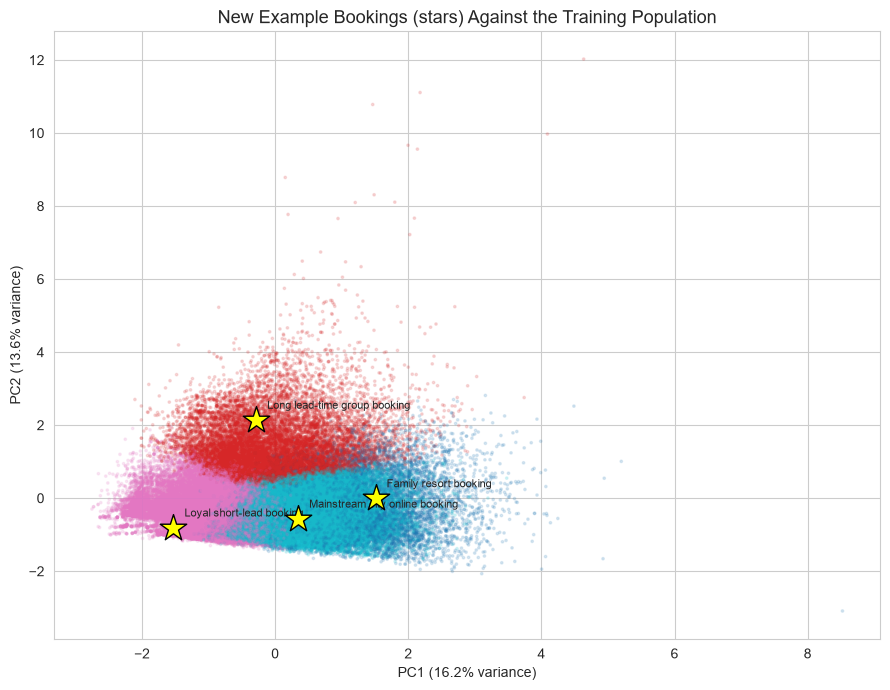

In [9]:
X_train = pd.read_csv(PREPROCESSED_FEATURES_PATH)

pca_2d = PCA(n_components=2, random_state=42)
X_train_pca = pca_2d.fit_transform(X_train)

# Project each example booking into the same PCA space for visualization
example_preprocessed = []
for booking_name, booking_data in example_bookings.items():
    row = pd.DataFrame([booking_data])[CORE_NUMERIC_FEATURES + CORE_CATEGORICAL_FEATURES]
    preprocessed = preprocessing_pipeline.transform(row)
    example_preprocessed.append(preprocessed[0])

example_preprocessed_array = np.array(example_preprocessed)
example_pca = pca_2d.transform(example_preprocessed_array)

fig, ax = plt.subplots(figsize=(9, 7))

training_cluster_labels = final_model.predict(pd.DataFrame(X_train.values, columns=preprocessed_feature_names))
ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=training_cluster_labels, cmap="tab10", s=3, alpha=0.15)

markers = ["*", "*", "*", "*"]
for i, (booking_name, _) in enumerate(example_bookings.items()):
    ax.scatter(example_pca[i, 0], example_pca[i, 1], marker="*", s=400, edgecolor="black",
               color="yellow", zorder=5)
    ax.annotate(booking_name, (example_pca[i, 0], example_pca[i, 1]), fontsize=8,
                xytext=(8, 8), textcoords="offset points")

ax.set_title("New Example Bookings (stars) Against the Training Population", fontsize=13)
ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "15_new_bookings_pca_visualization.png"))
plt.show()


**Finding:** all four example bookings (stars) land within the general footprint of the existing training population, in the region corresponding to their assigned cluster - they are realistic, in-distribution examples, not extreme edge cases that happen to be technically assignable but don't really resemble anything the model was trained on.

## 6. Important Limitations of This Deployment

Stated directly, as the project requires:

1. **Clusters reflect the training population, not a universal truth.** This model assigns new bookings based on the patterns learned from historical data covering 2015-2017 across two specific hotels. If the hotel's guest mix, pricing strategy, or market conditions change meaningfully over time, the *meaning* of "Cluster 0" could drift even if the model keeps assigning bookings to it - the segment's real-world characteristics might no longer match Notebook 14's description. This is exactly why Notebook 16 (Monitoring) exists.
2. **`room_type_mismatch` is often unavailable at true booking time**, and this function's default (assume no mismatch) is a documented assumption, not a certainty.
3. **This is assignment, not explanation.** The model places a new booking into the cluster whose centroid it's closest to - it does not verify that the booking is a strong, unambiguous fit. The distance-to-centroid figure returned by `assign_segment()` is a simple, useful signal for this (a small distance suggests a confident fit; a large distance suggests a borderline or unusual booking), but it is not a formal statistical confidence interval.
4. **Unseen categories are handled gracefully, not perfectly.** A brand-new category value is encoded as if that categorical feature carries no information for that specific prediction, rather than causing an error - a reasonable trade-off, but a real information loss worth knowing about.

## 7. Findings

- A single, reusable `assign_segment()` function successfully takes a raw new-booking dictionary through preprocessing, clustering, and segment naming in one call.
- All four realistic test bookings were assigned to the segment a human reading Notebook 14's profiles would also expect, a useful sanity check on the whole pipeline.
- A genuine, previously unaddressed complication was found and handled explicitly: `room_type_mismatch` usually isn't known at true booking time, and the function defaults it to 0 with an explicit flag rather than silently guessing.
- The pipeline's `handle_unknown="ignore"` setting (decided in Notebook 07) was confirmed to work as intended - an entirely unseen category value doesn't break the prediction.
- New example bookings, when projected into the same PCA space as the training data, land within the expected regions for their assigned clusters - they look like realistic members of the population, not edge cases.

## 8. Business Interpretation

This notebook turns the entire project into something the hotel can actually operate: a new booking comes in, this function runs, and within milliseconds the hotel knows which of the four evidence-backed segments it most resembles - along with an honest signal (distance to centroid) for how confidently it fits. Just as importantly, the limitations here are not afterthoughts - they directly shape how this system should be used: as a fast, useful signal to route and personalize a booking, not as an infallible classification to build irreversible decisions on without human oversight.

## 9. Conclusion

We packaged the preprocessing pipeline, final clustering model, and segment name mapping into one reusable function, demonstrated it successfully on four realistic new bookings, and surfaced and handled a real complication (the `room_type_mismatch` feature's availability at booking time) rather than assuming it away. The limitations of applying a clustering model to future, unseen data were stated explicitly rather than left implicit.

**Next notebook (16 - Monitoring and Maintenance):** we define how this segmentation system should be monitored over time - tracking feature drift, cluster-size drift, centroid movement, and business KPI changes - and lay out the criteria for deciding when the model needs to be retrained.